**Сначала переключитесь на графический процессор!**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Тетрадка выполнена с исходными данными и параметрами преподавателя: CIFAR-10 загружается
> `torchvision.datasets.CIFAR10`, обучение — на подвыборке из 10 000 изображений, оценка — на всех 10 000 тестовых;
> базовая CNN — 5 эпох, модификации архитектуры — тоже по 5 эпох (в задании — 3–5).
>
> Сделано: базовая CNN, карты активаций и фильтры первого слоя, три модификации архитектуры из списка (1 — шире,
> 5 — BatchNorm, 6 — Global Average Pooling) и их сочетание, дополнительная проверка на 15 эпохах (база и «шире +
> BN + GAP»), depthwise separable свёртки (в базовой модели, в самой точной из модификаций и в «шире + BN + GAP»),
> классификация тестовых изображений и фотографий «из интернета». Преподаватель не указал конкретные фотографии;
> взяты 19 снимков из выборки ImageNet, опубликованной на GitHub (`EliSchwartz/imagenet-sample-images`), по 1–2 на
> каждый класс CIFAR-10 (в ImageNet нет оленей, поэтому для класса deer — антилопы); они скачиваются по ссылкам в
> `../data/web_images`.
>
> Устройство выбирается в первой ячейке кода (cuda → mps → cpu); в функции обучения и оценки из заготовки добавлен
> перенос модели и батчей на это устройство. **Исправление ошибки заготовки:** при показе изображений было
> `img * 0.5 + 0.5`, хотя нормировка — по среднему и стандартному отклонению CIFAR-10; заменено на обратное
> преобразование с теми же mean/std, чтобы цвета были правильными.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# 6. Практическое занятие. Свёрточные нейронные сети (CNN)

**Цель работы:** Познакомиться с архитектурой CNN, научиться строить и обучать свёрточные сети для классификации изображений, визуализировать карты активации и экспериментировать с архитектурными решениями.

В этой практике мы будем использовать датасет CIFAR-10 (32x32 цветных изображения, 10 классов).

## 0. Импорты и подготовка данных

Импортируем необходимые библиотеки и загружаем CIFAR-10.

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import time


# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство
device = get_device()
print(f'Using device: {device}')

Using device: mps


In [3]:
# Загрузка данных CIFAR-10
# Для ускорения возьмём подвыборку (первые 10000 обучающих, 2000 тестовых)
# Но можно и полный датасет, если есть время.

CIFAR_MEAN = np.array([0.4914, 0.4822, 0.4465])
CIFAR_STD = np.array([0.247, 0.243, 0.261])
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(tuple(CIFAR_MEAN), tuple(CIFAR_STD))
])

train_full = datasets.CIFAR10(DATA, train=True, download=True, transform=transform)
test_full = datasets.CIFAR10(DATA, train=False, download=True, transform=transform)

# Для экспериментов возьмём подвыборку (ускорит обучение)
num_train = S(10000, 256)
num_val = S(2000, 128)
indices = torch.randperm(len(train_full))
train_indices = indices[:num_train]
val_indices = indices[num_train:num_train+num_val]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(train_full, val_indices)
test_dataset = test_full if not SMOKE else Subset(test_full, range(256))

print(f'Train samples: {len(train_dataset)}')
print(f'Val samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')

Train samples: 10000
Val samples: 2000
Test samples: 10000


In [4]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f'Train size: {len(train_dataset)}, Test size: {len(test_dataset)}')

Train size: 10000, Test size: 10000


## 1. Построение базовой CNN (10 мин)

Определим класс `SimpleCNN` с двумя свёрточными слоями, пулингом и полносвязными слоями.

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)  # 32x32 -> 32x32
        self.pool = nn.MaxPool2d(2)                               # 32x32 -> 16x16
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # 16x16 -> 16x16
        # После второго пулинга: 64 канала * 8 * 8
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        # x - входное изображение.
        x = self.pool(F.relu(self.conv1(x)))
        # теперь x - 32 карты признаков размером 16x16
        x = self.pool(F.relu(self.conv2(x)))
        # теперь x - 64 карты признаков размером 8x8

        # растягиваем тензор 64х8х8 в один большой вектор.
        x = x.view(x.size(0), -1)  # flatten

        x = self.dropout(F.relu(self.fc1(x)))
        # теперь х - вектор из 256 результатов активации нейронов
        x = self.fc2(x)
        # теперь х - вектор из 10 чисел, имеющих значения (-inf; inf).
        # Т.к. ниже написан выбор кросс-энтропии в качестве функции потерь
        # для многоклассовой классификации
        # criterion = nn.CrossEntropyLoss()
        # то к х после завершения данного метода
        # ещё дополнительно применится функция softmaх,
        # которая отмасштабирует значения х до отрезка [0; 1]
        return x

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Посчитаем количество параметров
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Количество обучаемых параметров: {count_parameters(model)}')

Количество обучаемых параметров: 1070794


## 2. Обучение и базовая оценка

Напишем функцию для одной эпохи обучения и оценки. Обучим модель на 5 эпохах и сохраним историю потерь.

Epoch 1/5, Train Loss: 1.8152, Val Loss: 1.4623, Val Acc: 0.4761


Epoch 2/5, Train Loss: 1.4295, Val Loss: 1.3547, Val Acc: 0.5127


Epoch 3/5, Train Loss: 1.3055, Val Loss: 1.2259, Val Acc: 0.5558


Epoch 4/5, Train Loss: 1.1793, Val Loss: 1.1656, Val Acc: 0.5851


Epoch 5/5, Train Loss: 1.0830, Val Loss: 1.1418, Val Acc: 0.5899

Финальная точность на тесте: 0.5899  (время обучения 11 с)
Сравнение с MLP: MLP давал точность около 0.5, наша CNN показывает значительное улучшение.


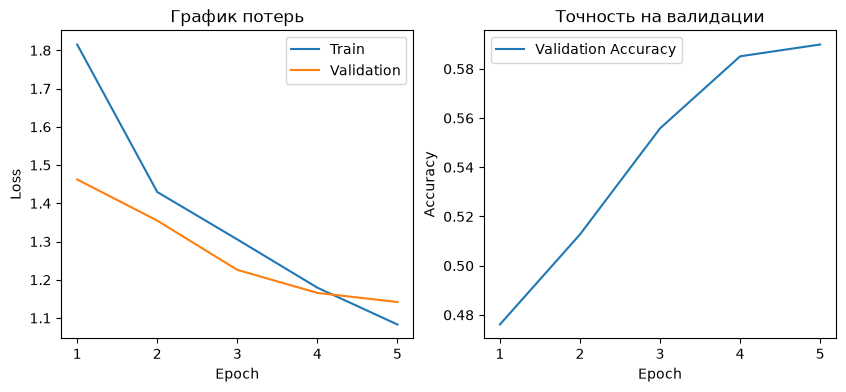

In [6]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return running_loss / len(loader.dataset), correct / total

num_epochs = S(5, 1)
train_losses = []
val_losses = []
val_accs = []

t0 = time.perf_counter()
for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, test_loader, criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

base_time = time.perf_counter() - t0
print(f'\nФинальная точность на тесте: {val_accs[-1]:.4f}  (время обучения {base_time:.0f} с)')

# Сравнение с MLP из занятия 5 (ожидаем ~0.5)
print('Сравнение с MLP: MLP давал точность около 0.5, наша CNN показывает значительное улучшение.')

# Построим графики потерь
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(range(1, num_epochs+1), train_losses, label='Train')
plt.plot(range(1, num_epochs+1), val_losses, label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('График потерь')

plt.subplot(1,2,2)
plt.plot(range(1, num_epochs+1), val_accs, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Точность на валидации')
plt.show()

## 3. Визуализация карт активации

Посмотрим, что именно выучил первый свёрточный слой. Для этого выберем несколько тестовых изображений и выведем карты активации (первые несколько каналов) после первого свёрточного слоя (до пулинга).

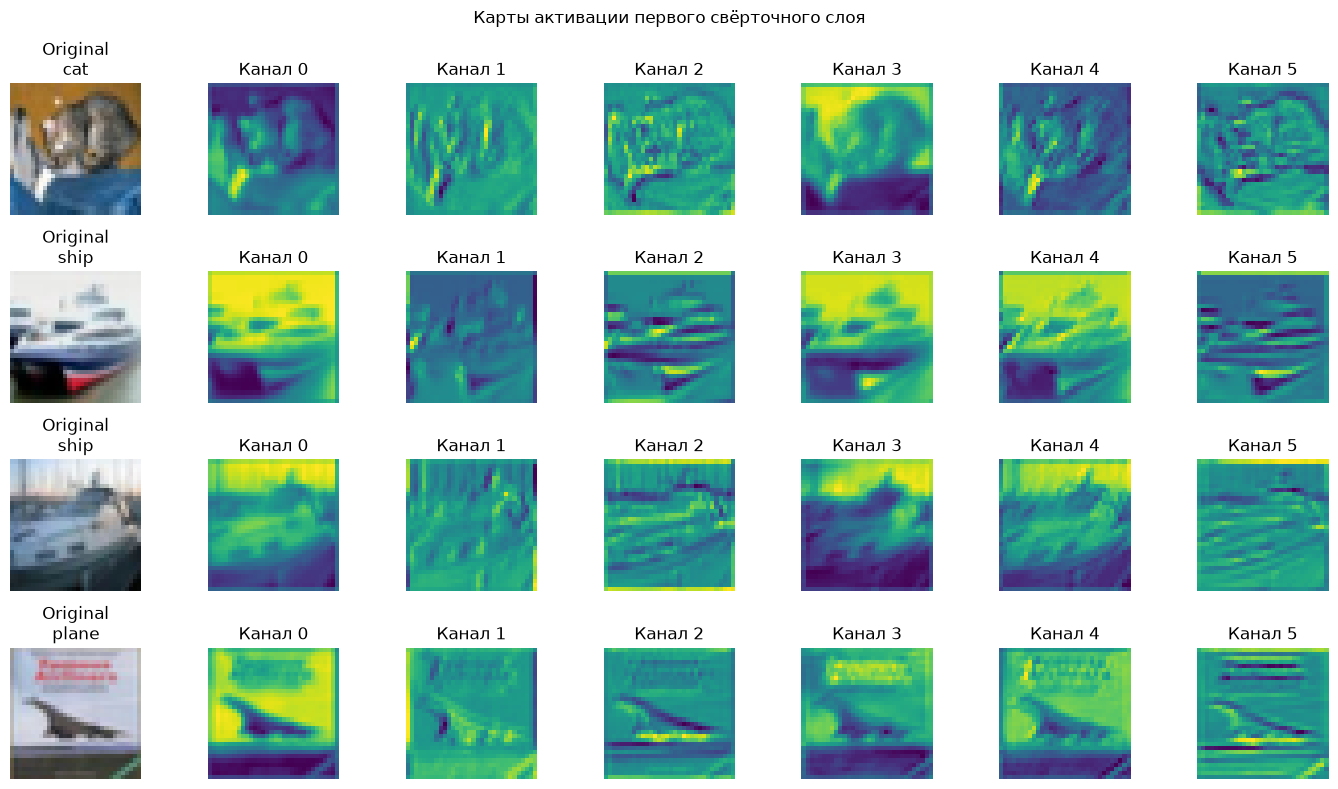

In [7]:
# Функция для получения активаций через forward hook
activations = {}
def hook_fn(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

# Регистрируем хук на conv1
hook = model.conv1.register_forward_hook(hook_fn('conv1'))

# Берём несколько тестовых изображений
dataiter = iter(test_loader)
images, labels = next(dataiter)
images = images[:4]  # возьмём 4 картинки

# Прогоняем через сеть (без градиентов)
with torch.no_grad():
    outputs = model(images.to(device))

# Получаем активации
acts = activations['conv1']  # (4, 32, 32, 32)

# Визуализируем исходные изображения и карты активаций (первые 6 каналов)
fig, axes = plt.subplots(4, 7, figsize=(14, 8))
for i in range(4):
    # Исходное изображение (восстанавливаем из нормализации)
    img = images[i].cpu().numpy().transpose(1,2,0)
    img = img * CIFAR_STD + CIFAR_MEAN  # обратная нормализация (в заготовке было *0.5+0.5, а нормировали по mean/std CIFAR)
    axes[i, 0].imshow(np.clip(img, 0, 1))
    axes[i, 0].set_title(f'Original\n{classes[labels[i]]}')
    axes[i, 0].axis('off')

    # 6 случайных каналов
    for j in range(6):
        channel_idx = j  # можно взять первые 6, но для разнообразия используем случайные
        ax = axes[i, j+1]
        ax.imshow(acts[i, channel_idx].cpu(), cmap='viridis')
        ax.set_title(f'Канал {channel_idx}')
        ax.axis('off')

plt.suptitle('Карты активации первого свёрточного слоя')
plt.tight_layout()
plt.show()

hook.remove()

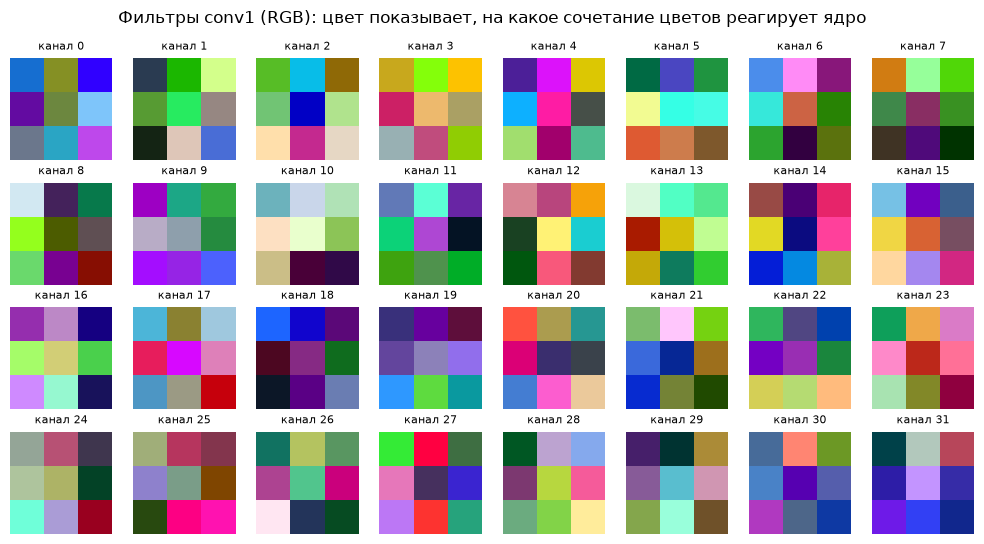

доля «цветовой» составляющей в фильтрах (0 — фильтр одинаков для R, G, B):
[0.82 0.65 0.77 0.95 0.91 0.78 0.72 0.75 0.68 0.9  0.39 0.78 0.74 0.78
 0.89 0.81 0.65 0.85 0.73 0.85 0.81 0.73 0.81 0.75 0.56 0.83 0.61 0.84
 0.68 0.57 0.88 0.76]


In [8]:
# Дополнительно: сами фильтры первого слоя (32 ядра 3x3 по трём цветовым каналам)
w = model.conv1.weight.detach().cpu().numpy()      # (32, 3, 3, 3)
fig, axes = plt.subplots(4, 8, figsize=(10, 5.5))
for k, ax in enumerate(axes.flat):
    f = w[k].transpose(1, 2, 0)
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # нормируем каждый фильтр в [0, 1], чтобы видеть цвет
    ax.imshow(f, interpolation='nearest'); ax.set_title(f'канал {k}', fontsize=8); ax.axis('off')
plt.suptitle('Фильтры conv1 (RGB): цвет показывает, на какое сочетание цветов реагирует ядро')
plt.tight_layout(); plt.show()

# Насколько «цветные» фильтры: доля нормы, приходящаяся на отличие каналов друг от друга
l2 = lambda a: np.sqrt((a ** 2).sum(axis=(1, 2, 3)))
color_part = l2(w - w.mean(axis=1, keepdims=True)) / l2(w)
print('доля «цветовой» составляющей в фильтрах (0 — фильтр одинаков для R, G, B):')
print(np.round(color_part, 2))

Задание: Опишите, какие признаки активируют разные каналы (контуры, текстуры, цвета). Заметно ли, что карты примерно соответствуют очертаниям объектов? (Из-за маленького размера 32x32 и нормализации это может быть неочевидно, но попытайтесь увидеть границы.)

**Карты активаций первого слоя** (базовая CNN после 5 эпох, каналы 0–5 для четырёх тестовых картинок) показывают три вида признаков.

- **Яркость и цвет больших областей.** Каналы 0, 3 и 4 ярко светятся на светлом фоне — на небе над кораблями и на светлом плакате за самолётом. Канал 3 так же выделяет оранжевую стену за кошкой. Тёмный корпус корабля и тёмный силуэт самолёта при этом почти не активируют эти каналы. Получается «маска» объекта по контрасту с фоном.
- **Контуры, ориентированные в определённом направлении.** Каналы 2 и 5 выделяют горизонтальные границы: палубы и ватерлинию корабля, строки текста на плакате, нижний край самолёта. Канал 1 реагирует на вертикальные и наклонные штрихи, в том числе на полосы шерсти кошки.
- **Текстура.** На кошке каналы 1, 2 и 4 дают пёстрый рисунок из мелких пятен — это отклик на текстуру шерсти, а не на контур.

**Видны ли очертания объектов?** Да, для картинок с простым фоном очень отчётливо: силуэты самолёта и кораблей узнаются почти на всех шести каналах. У кошки на пёстром фоне контур виден хуже, карты заполнены текстурой. По краям многих карт видна светлая или тёмная рамка — это эффект нулевого дополнения (`padding = 1`): на границе свёртка «видит» нули вместо пикселей.

**Фильтры conv1** (32 ядра 3×3×3) на картинке выглядят как случайные цветные пятна: в ядре 3×3 трудно увидеть привычный «детектор края». Но почти все фильтры сильно зависят от цвета. Доля «цветовой» составляющей (насколько ядро различается для R, G и B) — от 0,39 до 0,95, в среднем 0,76; у 13 из 32 фильтров она больше 0,8. Значит, первый слой реагирует не на яркость вообще, а на определённые сочетания цветов и цветовые переходы. Это согласуется с картами, где часть каналов выделяет области определённого цвета.

## 4. Эксперименты с архитектурой

Теперь вы самостоятельно модифицируете архитектуру и сравниваете результаты. Выберите **2-3** варианта из предложенных ниже, реализуйте соответствующие модели, обучите их на **3-5 эпохах** (для экономии времени) и запишите точность и количество параметров.

**Варианты модификаций:**
1. Увеличить число каналов: `conv1(3, 64)`, `conv2(64, 128)`.
2. Добавить третий свёрточный блок (Conv+Pool).
3. Заменить MaxPool на `stride=2` в свёртке (убрать явный пулинг).
4. Изменить размер ядра на 5 (учесть изменение padding для сохранения размера).
5. Добавить `BatchNorm2d` после каждой свёртки.
6. Заменить `Linear` на Global Average Pooling: `x = torch.mean(x, [2,3])` и затем один линейный слой.

Для каждой модели заполняйте таблицу (можно просто выводить на печать).

In [9]:
# Пример реализации одной из модификаций (увеличение числа каналов)
class WiderCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# Модификация 5: BatchNorm2d после каждой свёртки
class BNCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

# Модификация 6: Global Average Pooling вместо полносвязного слоя fc1
class GAPCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.mean(x, [2, 3])          # среднее по каждой карте признаков: (batch, 64, 8, 8) -> (batch, 64)
        return self.fc(x)

# Сочетание модификаций 1 + 5 + 6: шире, с BatchNorm и GAP (мало параметров при большем числе каналов)
class WideBNGAPCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(128)
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        return self.fc(torch.mean(x, [2, 3]))

def run_experiment(model_cls, epochs=5, lr=0.001, seed=0):
    """Обучает модель тем же способом, что и базовую (Adam, батч 64), и возвращает модель и историю."""
    torch.manual_seed(seed)
    m = model_cls().to(device)
    opt = optim.Adam(m.parameters(), lr=lr)
    hist = {'train_loss': [], 'test_loss': [], 'test_acc': []}
    t0 = time.perf_counter()
    for epoch in range(epochs):
        hist['train_loss'].append(train_epoch(m, train_loader, opt, criterion))
        tl, ta = evaluate(m, test_loader, criterion)
        hist['test_loss'].append(tl); hist['test_acc'].append(ta)
    hist['time'] = time.perf_counter() - t0
    return m, hist

EPOCHS_EXP = S(5, 1)
results = {'SimpleCNN (база)': (model, {'train_loss': train_losses, 'test_loss': val_losses, 'test_acc': val_accs, 'time': base_time})}
model_classes = {'SimpleCNN (база)': SimpleCNN}
for name, cls in [('1. WiderCNN (64/128 каналов)', WiderCNN), ('5. BatchNorm', BNCNN),
                  ('6. Global Average Pooling', GAPCNN), ('1+5+6: шире + BN + GAP', WideBNGAPCNN)]:
    model_classes[name] = cls
    m, h = run_experiment(cls, epochs=EPOCHS_EXP)
    results[name] = (m, h)
    print(f'{name}: точность {h["test_acc"][-1]:.4f}, {h["time"]:.0f} c')

# Пример вывода таблицы (можно оформить как pandas DataFrame, но для простоты просто print)
print(f"\n{'Модель':<32}{'Параметры':>12}{'Точность':>10}{'train loss':>12}{'test loss':>11}{'время, с':>10}")
print("-" * 87)
# Для каждой модели выведите строку
for name, (m, h) in results.items():
    print(f"{name:<32}{count_parameters(m):>12,}{h['test_acc'][-1]:>10.4f}{h['train_loss'][-1]:>12.4f}{h['test_loss'][-1]:>11.4f}{h['time']:>10.0f}")

1. WiderCNN (64/128 каналов): точность 0.6141, 12 c


5. BatchNorm: точность 0.5822, 11 c


6. Global Average Pooling: точность 0.4067, 9 c


1+5+6: шире + BN + GAP: точность 0.4469, 11 c

Модель                             Параметры  Точность  train loss  test loss  время, с
---------------------------------------------------------------------------------------
SimpleCNN (база)                   1,070,794    0.5899      1.0830     1.1418        11
1. WiderCNN (64/128 каналов)       2,175,626    0.6141      0.9688     1.1030        12
5. BatchNorm                       1,070,986    0.5822      1.2078     1.1618        11
6. Global Average Pooling             20,042    0.4067      1.6612     1.6389         9
1+5+6: шире + BN + GAP                77,322    0.4469      1.4349     1.5474        11


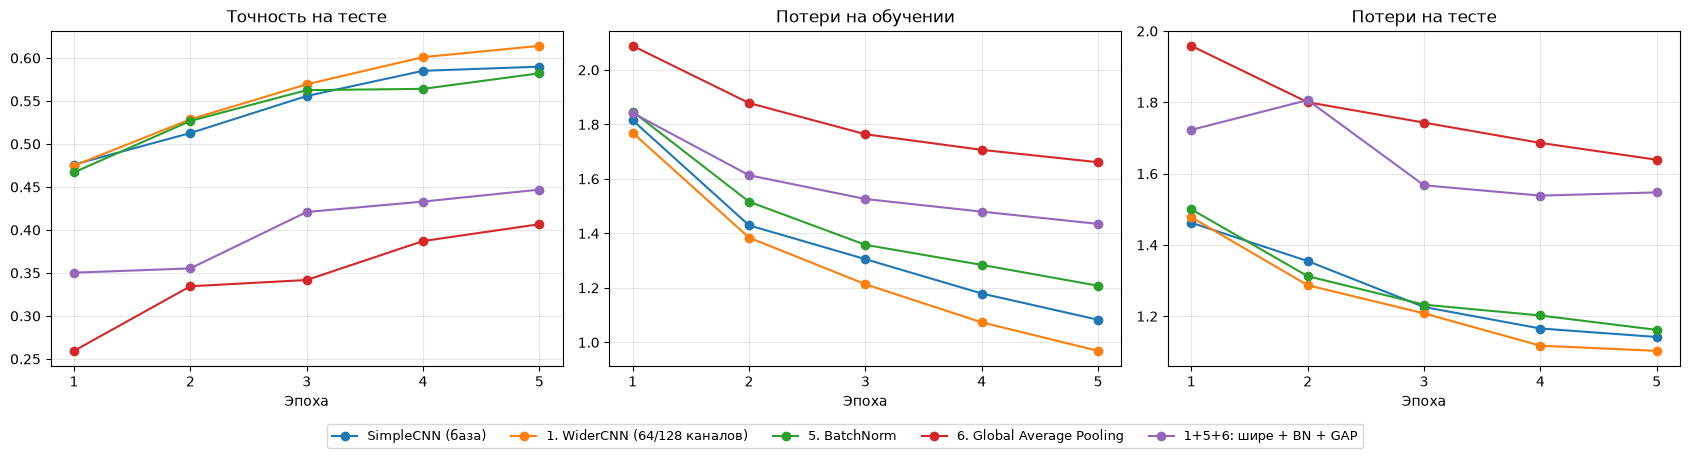

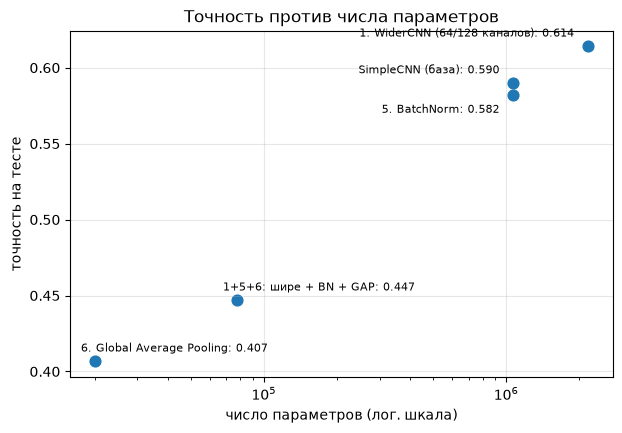

Самая точная модель за 5 эпох: 1. WiderCNN (64/128 каналов)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for name, (m, h) in results.items():
    e = range(1, len(h['test_acc']) + 1)
    axes[0].plot(e, h['test_acc'], 'o-', label=name)
    axes[1].plot(e, h['train_loss'], 'o-', label=name)
    axes[2].plot(e, h['test_loss'], 'o-', label=name)
for ax, t in zip(axes, ['Точность на тесте', 'Потери на обучении', 'Потери на тесте']):
    ax.set_title(t); ax.set_xlabel('Эпоха'); ax.set_xticks(range(1, EPOCHS_EXP + 1)); ax.grid(alpha=0.3)
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=len(results), fontsize=9, bbox_to_anchor=(0.5, -0.07))
plt.tight_layout(); plt.show()

names = list(results)
params = [count_parameters(results[n][0]) for n in names]
accs = [results[n][1]['test_acc'][-1] for n in names]
plt.figure(figsize=(7, 4.5))
plt.scatter(params, accs, s=60)
for n, p_, a in zip(names, params, accs):
    below = n.startswith('5.')          # подпись BatchNorm — под точкой, иначе она наложится на подпись базовой модели
    plt.annotate(f'{n}: {a:.3f}', (p_, a), xytext=(-10, -13) if below else (-10, 7), textcoords='offset points',
                 fontsize=8, ha='right' if p_ > 5e5 else 'left')
plt.xscale('log'); plt.xlabel('число параметров (лог. шкала)'); plt.ylabel('точность на тесте')
plt.title('Точность против числа параметров'); plt.grid(alpha=0.3)
plt.show()

print('Самая точная модель за 5 эпох:', max(results, key=lambda n: results[n][1]['test_acc'][-1]))

**Дополнительная проверка: дело в архитектуре или в числе эпох?** Модели с разным числом параметров и разной структурой
за 5 эпох могут быть обучены «в разной степени». Чтобы не сравнивать недообученные модели с обученными, базовая модель
и вариант «шире + BN + GAP» обучены ещё раз — по 15 эпох, тем же способом; по кривым можно проверить, выходит ли каждая из них на плато.

SimpleCNN (база): после 15 эпох точность 0.6401 (лучшая 0.6475 на эпохе 11), train loss 0.2829, test loss 1.3542 (минимум 1.0841 на эпохе 8), 25 c


1+5+6: шире + BN + GAP: после 15 эпох точность 0.5451 (лучшая 0.5451 на эпохе 15), train loss 1.2092, test loss 1.2959 (минимум 1.2959 на эпохе 15), 81 c


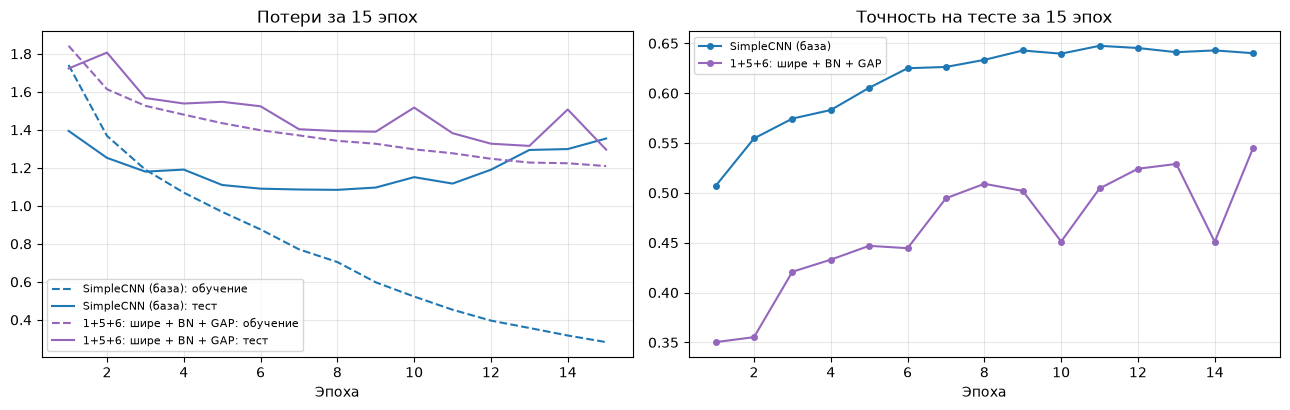

Лучшая из найденных моделей: SimpleCNN (база), 15 эп. — 0.6401


In [11]:
EPOCHS_LONG = S(15, 2)
long_results = {}
for name, cls in [('SimpleCNN (база)', SimpleCNN), ('1+5+6: шире + BN + GAP', WideBNGAPCNN)]:
    m, h = run_experiment(cls, epochs=EPOCHS_LONG)
    long_results[name] = (m, h)
    best_ep = int(np.argmax(h['test_acc']))
    print(f"{name}: после {EPOCHS_LONG} эпох точность {h['test_acc'][-1]:.4f} (лучшая {h['test_acc'][best_ep]:.4f} на эпохе {best_ep + 1}), "
          f"train loss {h['train_loss'][-1]:.4f}, test loss {h['test_loss'][-1]:.4f} (минимум {min(h['test_loss']):.4f} "
          f"на эпохе {int(np.argmin(h['test_loss'])) + 1}), {h['time']:.0f} c")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for (name, (m, h)), c in zip(long_results.items(), ['C0', 'C4']):
    e = range(1, EPOCHS_LONG + 1)
    axes[0].plot(e, h['train_loss'], '--', color=c, label=f'{name}: обучение')
    axes[0].plot(e, h['test_loss'], '-', color=c, label=f'{name}: тест')
    axes[1].plot(e, h['test_acc'], 'o-', color=c, ms=4, label=name)
axes[0].set_title('Потери за 15 эпох'); axes[1].set_title('Точность на тесте за 15 эпох')
for ax in axes:
    ax.set_xlabel('Эпоха'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# «Лучшая из найденных моделей» для раздела 6 — самая точная по итоговой точности среди всех обученных выше
candidates = {**{k + ', 5 эп.': v for k, v in results.items()}, **{k + ', 15 эп.': v for k, v in long_results.items()}}
best_name = max(candidates, key=lambda n: candidates[n][1]['test_acc'][-1])
best_cnn = candidates[best_name][0]
print('Лучшая из найденных моделей:', best_name, f"— {candidates[best_name][1]['test_acc'][-1]:.4f}")

Все модели обучены одинаково: Adam, lr = 0,001, батч 64, 10 000 обучающих изображений, точность — на всех 10 000 тестовых.

| модель | параметров | точность, 5 эпох | train loss | test loss | время |
|---|---|---|---|---|---|
| SimpleCNN (база) | 1 070 794 | 0,590 | 1,083 | 1,142 | 11 с |
| **1. шире (64/128 каналов)** | 2 175 626 | **0,614** | 0,969 | 1,103 | 12 с |
| 5. BatchNorm | 1 070 986 | 0,582 | 1,208 | 1,162 | 11 с |
| 6. Global Average Pooling | 20 042 | 0,407 | 1,661 | 1,639 | 9 с |
| 1 + 5 + 6: шире + BN + GAP | 77 322 | 0,447 | 1,435 | 1,547 | 11 с |

- **Шире (модификация 1)** — единственная, что дала прирост: +2,4 п. п. за 5 эпох. Больше каналов — больше разных детекторов признаков, и модель быстрее снижает train loss (0,97 против 1,08). Но число параметров удвоилось, и почти весь прирост приходится не на свёртки, а на первый полносвязный слой: на него подаётся 128·8·8 = 8192 признака вместо 4096.
- **BatchNorm (5)** за 5 эпох ничего не дал: 0,582 против 0,590. Разница меньше 1 п. п., это в пределах случайного разброса одного запуска. С Adam и такой маленькой сетью обучение и без BatchNorm идёт устойчиво, а ускорение, ради которого BatchNorm обычно добавляют, здесь не проявилось.
- **Global Average Pooling (6)** уменьшает число параметров в 53 раза: исчезает слой `fc1` на 1,05 млн весов. Но точность падает до 0,407, и train loss тоже высокий (1,66). Это недообучение: после двух свёрточных слоёв 64 канала с усреднением по всей карте 8×8 теряют информацию о расположении признаков, а ёмкости на её восстановление не хватает.
- **Сочетание 1 + 5 + 6** — 77 тыс. параметров, в 14 раз меньше базы, точность 0,447. Больше каналов частично компенсирует потерю полносвязного слоя.

**Дело в архитектуре или в числе эпох?** Проверка на 15 эпохах:
- **База:** 0,640 (лучшая 0,648 на 11-й эпохе). Train loss падает до 0,28, а test loss после минимума 1,084 на 8-й эпохе растёт до 1,354. С 8-й эпохи начинается переобучение: точность стоит на 0,64, а уверенность в ошибочных ответах растёт.
- **«Шире + BN + GAP»:** 0,545, и точность ещё растёт на 15-й эпохе. Train loss (1,21) и test loss (1,30) близки — переобучения нет, модель недообучена. Её точность на тесте сильно скачет (0,45 на 10-й и 14-й эпохах, 0,53–0,55 рядом с ними).

То есть сравнение за 5 эпох несправедливо к маленьким моделям с GAP: за 10 дополнительных эпох база прибавила 5 п. п., а «шире + BN + GAP» — 10 п. п. Но и через 15 эпох она отстаёт от базы на 9,5 п. п.

**Лучшая из найденных моделей** — базовая CNN после 15 эпох (0,640), она используется в разделе 6. Вариант «шире» на 15 эпохах не проверялся, и, возможно, он был бы ещё точнее.

## 5. Depthwise Separable Convolution

Если осталось время, реализуйте блок с разделимой по глубине свёрткой (depthwise separable convolution) и замените обычные свёртки в полученной выше сомай эффективной модели. Сравните число параметров и точность.

In [12]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels, in_channels, kernel_size,
                                    padding=kernel_size//2, groups=in_channels)
        self.pointwise = nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x):
        return self.pointwise(F.relu(self.depthwise(x)))

class DepthwiseCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = DepthwiseSeparableConv(3, 32, 3)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = DepthwiseSeparableConv(32, 64, 3)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

model_ds = DepthwiseCNN()
print(f'Параметры DepthwiseCNN: {count_parameters(model_ds)}')
print(f'Параметры базовой CNN: {count_parameters(SimpleCNN())}')
# Обучите модель (можно на 3 эпохах) и сравните точность

Параметры DepthwiseCNN: 1053992
Параметры базовой CNN: 1070794


**Задача**: добавить цикл обучения к этому варианту свёртки и сравнить полученную точность.

In [13]:
# Обучаем DepthwiseCNN (замена свёрток в базовой модели) тем же способом
model_ds, hist_ds = run_experiment(DepthwiseCNN, epochs=EPOCHS_EXP)
results['DepthwiseCNN (база + DS-свёртки)'] = (model_ds, hist_ds)

def to_depthwise(model_cls):
    # та же архитектура, но свёртки conv1 и conv2 заменены на depthwise separable (ядро 3, размер карт сохраняется)
    class DSModel(model_cls):
        def __init__(self):
            super().__init__()
            for name in ('conv1', 'conv2'):
                conv = getattr(self, name)
                setattr(self, name, DepthwiseSeparableConv(conv.in_channels, conv.out_channels, conv.kernel_size[0]))
    DSModel.__name__ = 'Depthwise' + model_cls.__name__
    return DSModel

# «Самая эффективная модель» из раздела 4 — самая точная из модификаций по итогам 5 эпох
section4 = [n for n in model_classes if n != 'SimpleCNN (база)']
best4 = max(section4, key=lambda n: results[n][1]['test_acc'][-1])
print('Самая точная модификация из раздела 4:', best4)
pairs = [('SimpleCNN (база)', 'DepthwiseCNN (база + DS-свёртки)')]
for name in dict.fromkeys([best4, '1+5+6: шире + BN + GAP']):
    # «шире + BN + GAP» — дополнительно: в ней нет большого полносвязного слоя, почти все параметры — в свёртках
    ds_name = f'DS-свёртки в «{name}»'
    results[ds_name] = run_experiment(to_depthwise(model_classes[name]), epochs=EPOCHS_EXP)
    pairs.append((name, ds_name))

def conv_params(m):
    return sum(p.numel() for n, p in m.named_parameters() if n.startswith(('conv', 'bn')))

print(f"\n{'Модель':<40}{'всего парам.':>13}{'в свёртках':>12}{'Точность':>10}{'время, с':>10}")
for pair in pairs:
    for name in pair:
        m, h = results[name]
        print(f"{name:<40}{count_parameters(m):>13,}{conv_params(m):>12,}{h['test_acc'][-1]:>10.4f}{h['time']:>10.0f}")

Самая точная модификация из раздела 4: 1. WiderCNN (64/128 каналов)



Модель                                   всего парам.  в свёртках  Точность  время, с
SimpleCNN (база)                            1,070,794      19,392    0.5899        11
DepthwiseCNN (база + DS-свёртки)            1,053,992       2,590    0.4653        25
1. WiderCNN (64/128 каналов)                2,175,626      75,648    0.6141        12
DS-свёртки в «1. WiderCNN (64/128 каналов)»    2,109,224       9,246    0.5077        32
1+5+6: шире + BN + GAP                         77,322      76,032    0.4469        11
DS-свёртки в «1+5+6: шире + BN + GAP»          10,920       9,630    0.4159        35


| модель | параметров всего | в свёртках | точность, 5 эпох | время |
|---|---|---|---|---|
| SimpleCNN (база) | 1 070 794 | 19 392 | **0,590** | 11 с |
| база + DS-свёртки | 1 053 992 | 2 590 | 0,465 | 25 с |
| шире (самая точная модификация) | 2 175 626 | 75 648 | **0,614** | 12 с |
| шире + DS-свёртки | 2 109 224 | 9 246 | 0,508 | 32 с |
| шире + BN + GAP | 77 322 | 76 032 | **0,447** | 11 с |
| шире + BN + GAP + DS-свёртки | 10 920 | 9 630 | 0,416 | 35 с |

- **Параметры.** Разделимая свёртка (поканальная 3×3 + точечная 1×1) уменьшает число весов свёрточных слоёв примерно в 7,5–8 раз (19 392 → 2 590, 75 648 → 9 246). Но в базе и в широкой модели почти все параметры сидят в полносвязном слое, поэтому общее число параметров уменьшилось лишь на 1,5–3 %. Заметная экономия только в модели с GAP, где почти всё — свёртки: 77 тыс. → 11 тыс., в 7 раз.
- **Точность** падает везде: на 12,5 п. п. в базе, на 10,6 п. п. в широкой модели и на 3,1 п. п. в модели с GAP. Сильнее всего страдает первый слой. У него всего 3 входных канала, и поканальная свёртка — это три фильтра 3×3, по одному на каждый цвет. Пространственно-цветовые сочетания, которые видны в фильтрах обычного `conv1` (цветовые переходы, края определённого цвета), такой слой выучить не может: цвета смешиваются только после свёртки, в слое 1×1. Поэтому в сетях вроде MobileNet первую свёртку обычно оставляют обычной.
- **Время обучения** выросло в 2–3 раза (25–35 с против 11–12 с), хотя вычислений стало меньше. По-видимому, групповая свёртка (`groups = in_channels`) на графическом процессоре Mac (MPS) реализована менее эффективно, чем обычная.

**Итог.** Разделимые свёртки выгодны там, где свёрточные слои составляют основную часть модели: в модели с GAP — в 7 раз меньше параметров ценой 3 п. п. точности. В маленькой сети с большим полносвязным слоем они почти не уменьшают модель, а точность заметно теряют.

## 6. Классификация изображений

**Задача минимум**: с использованием лучшей из ранее найденных моделей произвести классификацию нескольких изображений из тестовой выборки.<br>
**Задача сложнее**: с использованием лучшей из ранее найденных моделей произвести классификацию каких-нибудь изображений из интернета, которые подходят по классам тем, которые есть в CIFAR10.
Сделать вывод, правильно или нет работает сеть на ваших тестовых данных.

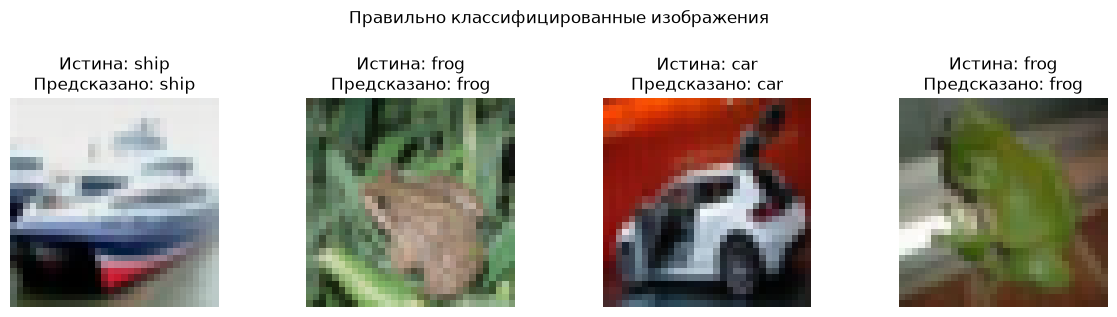

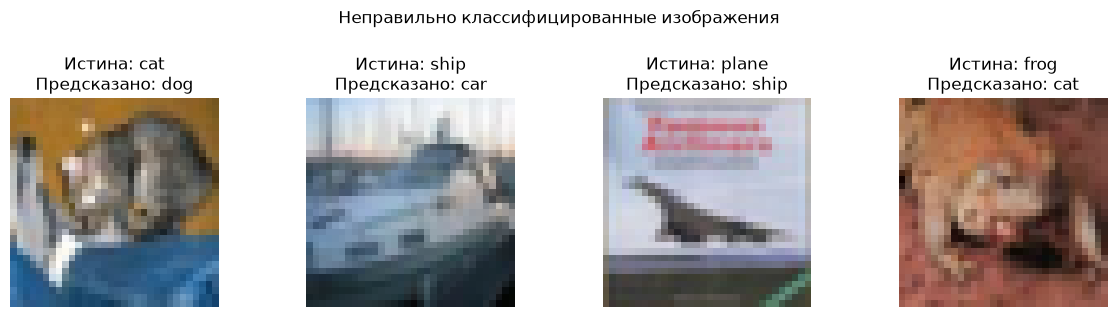

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Лучшая из найденных моделей (см. таблицу в разделе 4)
model = best_cnn
# Переводим модель в режим оценки
model.eval()

# Получаем один батч из тестового набора
dataiter = iter(DataLoader(test_dataset, batch_size=64, shuffle=False))
images, labels = next(dataiter)

# Делаем предсказания
with torch.no_grad():
    outputs = model(images.to(device))
    _, predicted = torch.max(outputs, 1)

# Преобразуем тензоры в numpy для визуализации
images = images.numpy()
labels = labels.numpy()
predicted = predicted.cpu().numpy()

# Найдём индексы правильно и неправильно классифицированных
correct_indices = np.where(predicted == labels)[0]
incorrect_indices = np.where(predicted != labels)[0]

# Выберем по 4 примера (если есть)
num_to_show = 4
correct_to_show = correct_indices[:num_to_show] if len(correct_indices) >= num_to_show else correct_indices
incorrect_to_show = incorrect_indices[:num_to_show] if len(incorrect_indices) >= num_to_show else incorrect_indices

# Функция отображения
def show_examples(indices, title):
    plt.figure(figsize=(12, 3))
    for i, idx in enumerate(indices):
        plt.subplot(1, len(indices), i+1)
        # Восстанавливаем изображение из нормализации
        img = images[idx].transpose(1, 2, 0)
        img = img * CIFAR_STD + CIFAR_MEAN  # обратная нормализация
        plt.imshow(np.clip(img, 0, 1))
        plt.title(f'Истина: {classes[labels[idx]]}\nПредсказано: {classes[predicted[idx]]}')
        plt.axis('off')
    plt.suptitle(title, y=1.04)   # над заголовками картинок, чтобы не накладывался
    plt.tight_layout()
    plt.show()

# Показываем правильно классифицированные
if len(correct_to_show) > 0:
    show_examples(correct_to_show, 'Правильно классифицированные изображения')
else:
    print("Нет правильно классифицированных примеров в этом батче.")

# Показываем неправильно классифицированные
if len(incorrect_to_show) > 0:
    show_examples(incorrect_to_show, 'Неправильно классифицированные изображения')
else:
    print("Нет неправильно классифицированных примеров в этом батче.")

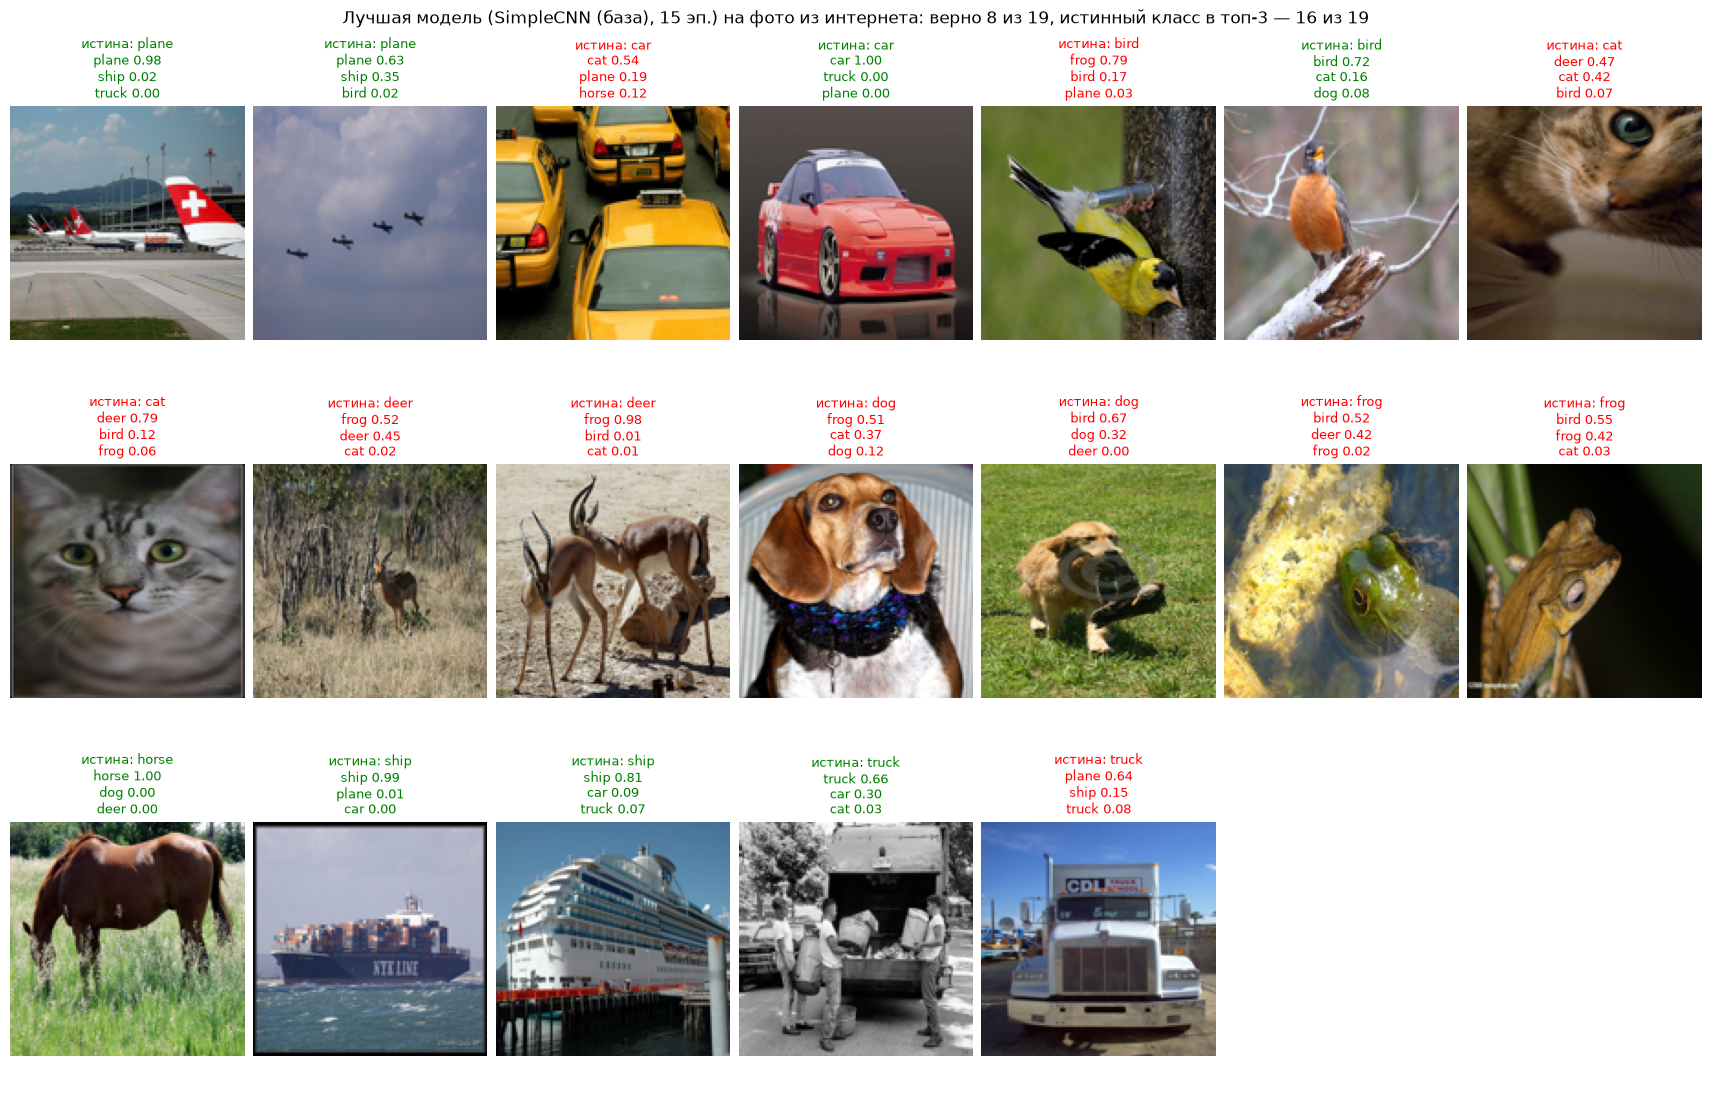

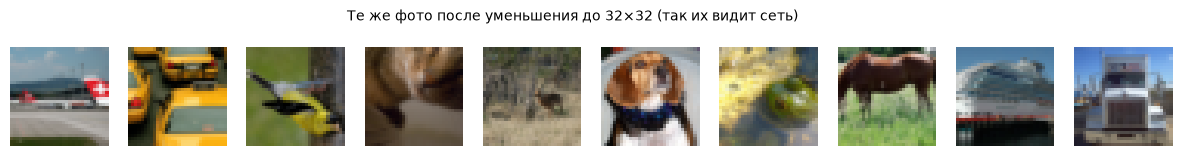

In [15]:
# Задача сложнее: фотографии «из интернета» — 19 снимков из выборки ImageNet (репозиторий EliSchwartz/imagenet-sample-images),
# по 1–2 на каждый класс CIFAR-10. В ImageNet нет оленей, поэтому для класса deer взяты антилопы (импала и газель).
import urllib.request
from pathlib import Path
from PIL import Image

WEB_BASE = 'https://raw.githubusercontent.com/EliSchwartz/imagenet-sample-images/master/'
WEB_IMAGES = {
    'airplane': ['n02690373_airliner.JPEG', 'n04552348_warplane.JPEG'],
    'automobile': ['n04285008_sports_car.JPEG', 'n02930766_cab.JPEG'],
    'bird': ['n01531178_goldfinch.JPEG', 'n01558993_robin.JPEG'],
    'cat': ['n02123045_tabby.JPEG', 'n02124075_Egyptian_cat.JPEG'],
    'deer': ['n02422699_impala.JPEG', 'n02423022_gazelle.JPEG'],
    'dog': ['n02088364_beagle.JPEG', 'n02099601_golden_retriever.JPEG'],
    'frog': ['n01641577_bullfrog.JPEG', 'n01644373_tree_frog.JPEG'],
    'horse': ['n02389026_sorrel.JPEG'],
    'ship': ['n03095699_container_ship.JPEG', 'n03673027_liner.JPEG'],
    'truck': ['n04467665_trailer_truck.JPEG', 'n03417042_garbage_truck.JPEG'],
}

def get_web_images():
    folder = Path(DATA) / 'web_images'
    folder.mkdir(parents=True, exist_ok=True)
    for cls, names in WEB_IMAGES.items():
        for fname in names:
            path = folder / f'{cls}__{fname}'
            if not path.exists():
                urllib.request.urlretrieve(WEB_BASE + fname, path)
    return folder

web_dir = get_web_images()
files = sorted(Path(web_dir).glob('*.JPEG'))
to_input = transforms.Compose([transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor(),
                               transforms.Normalize(tuple(CIFAR_MEAN), tuple(CIFAR_STD))])
web_x = torch.stack([to_input(Image.open(f).convert('RGB')) for f in files])
web_y = [classes.index(f.name.split('__')[0].replace('airplane', 'plane').replace('automobile', 'car')) for f in files]

best_cnn.eval()
with torch.no_grad():
    probs = F.softmax(best_cnn(web_x.to(device)), dim=1).cpu().numpy()

fig, axes = plt.subplots(3, 7, figsize=(17, 11), constrained_layout=True)
n_ok, n_top3 = 0, 0
for k, ax in enumerate(axes.flat):
    ax.axis('off')
    if k >= len(files):
        continue
    img = Image.open(files[k]).convert('RGB')
    top = np.argsort(-probs[k])[:3]
    ok = top[0] == web_y[k]
    n_ok += ok; n_top3 += web_y[k] in top
    ax.imshow(np.asarray(img.resize((128, 128))))
    ax.set_title(f"истина: {classes[web_y[k]]}\n" + "\n".join(f"{classes[c]} {probs[k, c]:.2f}" for c in top),
                 fontsize=9, color='green' if ok else 'red')
plt.suptitle(f'Лучшая модель ({best_name}) на фото из интернета: верно {n_ok} из {len(files)}, '
             f'истинный класс в топ-3 — {n_top3} из {len(files)}')
plt.show()

# Так эти фото выглядят для сети — уменьшенными до 32x32
fig, axes = plt.subplots(1, 10, figsize=(15, 1.8))
for ax, k in zip(axes, range(0, len(files), 2)):
    ax.imshow(np.clip(web_x[k].numpy().transpose(1, 2, 0) * CIFAR_STD + CIFAR_MEAN, 0, 1)); ax.axis('off')
plt.suptitle('Те же фото после уменьшения до 32×32 (так их видит сеть)', fontsize=10); plt.show()

Используется лучшая модель — базовая CNN после 15 эпох (0,640 на тесте).

**Тестовые изображения.** Из первого батча показаны по 4 верных и неверных ответа.
- **Верно:** корабль, две лягушки, автомобиль.
- **Ошибки:** кошка → собака, корабль на фоне неба и мачт → автомобиль, самолёт на плакате с текстом → корабль, рыжая лягушка → кошка.

Ошибки понятны: кошек и собак в 32×32 трудно различить, самолёт снят в необычном окружении, а лягушка по цвету и текстуре похожа на шерсть.

**Фото «из интернета»** (19 снимков из выборки ImageNet): верно **8 из 19** (42 %), истинный класс в тройке лучших — **16 из 19**.
- **Верно и уверенно:** лайнер в аэропорту (plane 0,98), лошадь на траве (1,00), спортивный автомобиль (1,00), контейнеровоз (0,99), круизный лайнер (0,81). Менее уверенно: истребители в небе (0,63), малиновка (0,72), мусоровоз (0,66).
- **Ошибки.**
  - Обе кошки сняты крупным планом и распознаны как олени (0,47 и 0,79).
  - Импала и газель → лягушка (0,52 и 0,98).
  - Бигль → лягушка (0,51), золотистый ретривер → птица (0,67).
  - Обе лягушки → птица, щегол → лягушка.
  - Седельный тягач на фоне голубого неба → самолёт (0,64).
  - Несколько жёлтых такси → кошка (0,54).

**Правильно ли работает сеть?** Частично. Она хорошо распознаёт сцены, типичные для CIFAR-10: самолёт в небе или на аэродроме, корабль на воде, лошадь на траве, машина на однотонном фоне. По ошибкам видно, что сеть во многом опирается на фон и цвет, а не на форму. Животные на зелёной или жёлто-бурой природе превращаются в лягушек и птиц, грузовик на фоне неба — в самолёт. Кроме того, фото из ImageNet отличаются от CIFAR-10 кадрированием: кошки и собаки сняты крупным планом (в CIFAR они обычно целиком), а после уменьшения до 32×32 и обрезки по центру часть объекта теряется. Отсюда разрыв: 64 % на тесте CIFAR-10 и 42 % на этих фото, хотя в тройку лучших истинный класс попадает почти всегда.

## 6. Выводы

В этой ячейке напишите краткие выводы по работе:
- Почему CNN работает лучше MLP на CIFAR-10?
- Какие модификации архитектуры дали наибольший прирост качества и почему?
- Как изменилось количество параметров при различных изменениях?
- Что показала визуализация карт активации?

Используйте термины: рецептивное поле, локальность, разделение весов, регуляризация (dropout, batch norm), ёмкость модели, переобучение.

1. **Почему CNN лучше MLP на CIFAR-10.** На тех же 10 000 обучающих изображениях базовая CNN за 5 эпох и 11 с даёт 0,590, за 15 эпох — 0,640. Лучший MLP из практики 5 после подбора инициализации, BatchNorm, Dropout и аугментации, с обучением до 28 эпох, — 0,508. Свёртка использует **локальность**: каждый нейрон смотрит на маленькое окно 3×3, где соседние пиксели связаны. **Разделение весов**: одно и то же ядро применяется во всех позициях, поэтому признак («край», «пятно цвета») находится в любом месте картинки, а весов нужно в тысячи раз меньше, чем полносвязному слою. После двух слоёв свёртки и пулинга **рецептивное поле** нейрона растёт с 3×3 до 10×10 пикселей, и сеть строит признаки иерархически: от краёв и цветовых пятен к частям объектов. MLP же должен заново выучивать один и тот же признак для каждого положения.
2. **Какие модификации помогли.** Прирост дало только увеличение числа каналов: 0,614 против 0,590 за 5 эпох. Больше каналов — больше **ёмкость модели**, больше разных детекторов признаков. BatchNorm на 5 эпохах ничего не изменил (0,582). Global Average Pooling резко снижает ёмкость и без длительного обучения ведёт к недообучению (0,407 за 5 эпох, 0,545 за 15 эпох в сочетании «шире + BN + GAP»).
3. **Число параметров.**
   - В базовой CNN 98 % параметров (1,05 млн из 1,07 млн) сидят в первом полносвязном слое, а не в свёртках (19 тыс.).
   - Удвоение каналов удваивает модель (2,18 млн) — в основном через тот же полносвязный слой.
   - BatchNorm добавляет всего 192 параметра.
   - GAP убирает полносвязный слой и сокращает модель в 53 раза (20 тыс.).
   - Разделимые свёртки сокращают свёрточные слои в 7,5–8 раз, но заметно уменьшают только модель с GAP (77 тыс. → 11 тыс.), и точность при этом падает на 3–12 п. п.
4. **Переобучение и регуляризация.** Базовая CNN с Dropout 0,5 всё равно переобучается: после 8-й эпохи test loss растёт (1,08 → 1,35), а train loss падает до 0,28. Модели с GAP не переобучаются даже за 15 эпох: у них мало параметров, и им, наоборот, не хватает ёмкости. Для базы следовало бы добавить раннюю остановку или аугментацию, как в практике 5.
5. **Карты активаций** показали, что первый слой выделяет яркие и тёмные области (силуэт объекта на фоне), горизонтальные и вертикальные границы и текстуру. Фильтры сильно зависят от цвета (цветовая доля в среднем 0,76). Очертания самолёта и кораблей видны на картах отчётливо.
6. **Проверка на фото из интернета** (8 из 19, в тройке лучших — 16 из 19) показала ограничения маленькой CNN: она во многом опирается на фон и цвет и плохо переносится на снимки с другим кадрированием.

Новые навыки/умения/знания.
Пожелания по содержимому лекции ипрактики.

**Что нового.**
- Научился смотреть внутрь свёрточной сети: снимать активации слоя через `register_forward_hook` и рисовать фильтры, а не только смотреть на итоговую точность.
- Увидел на числах, где на самом деле находятся параметры маленькой CNN (в полносвязном слое), и почему GAP и разделимые свёртки уменьшают модель по-разному.
- Убедился, что сравнивать архитектуры по 5 эпохам рискованно: маленькие модели к этому моменту ещё недообучены, а большая уже начинает переобучаться.

**Что можно улучшить в практике.**
- В заготовке при показе изображений была денормализация `img * 0.5 + 0.5`, хотя нормировка — по среднему и СКО CIFAR-10. Цвета получались искажёнными (исправлено, см. начало тетрадки).
- В разделе 5 стоит уточнить, что считать «самой эффективной моделью» (самую точную или лучшую по соотношению точности и размера) и в какие слои ставить разделимые свёртки. Особенно стоит оговорить первый слой с тремя входными каналами, где замена сильнее всего вредит точности.
- Для задания с фото из интернета полезно сразу предупредить, что фото нужно кадрировать «как в CIFAR» (объект целиком, по центру), иначе результат определяется скорее различием кадрирования, чем качеством модели.